Exercises : 

Conceptual: 

Exercise 1:
(a): 

We wish to prove:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2$

where $\bar{x}_{kj} = \frac{1}{|C_k|} \sum_{i \in C_k} x_{ij}$ is the mean for feature $j$ in cluster $C_k$.

It is enough to prove the identity for a single feature $j$. The full result follows by summing over all $p$ features $j = 1, \dots, p$.

For a fixed feature $j$, expand the term $(x_{ij} - x_{i'j})^2$ by adding and subtracting $\bar{x}_{kj}$:

$(x_{ij} - x_{i'j})^2 = \Big( (x_{ij} - \bar{x}_{kj}) - (x_{i'j} - \bar{x}_{kj}) \Big)^2$

$(x_{ij} - x_{i'j})^2 = (x_{ij} - \bar{x}_{kj})^2 - 2(x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) + (x_{i'j} - \bar{x}_{kj})^2$

$\sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})^2 - 2 \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) + \sum_{i, i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2$

Let's evaluate each of the three terms on the right-hand side:

1. **First Term:** Since $(x_{ij} - \bar{x}_{kj})^2$ does not depend on $i'$, summing over $i' \in C_k$ yields a factor of $|C_k|$:
   $$
   \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2
   $$

2. **Third Term:** By symmetry with the first term:
   $$
   \sum_{i, i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2 = |C_k| \sum_{i' \in C_k} (x_{i'j} - \bar{x}_{kj})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2
   $$

3. **Middle Term:** We can split the double sum:
   $$
   \sum_{i, i' \in C_k} (x_{ij} - \bar{x}_{kj})(x_{i'j} - \bar{x}_{kj}) = \left( \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj}) \right) \left( \sum_{i' \in C_k} (x_{i'j} - \bar{x}_{kj}) \right)
   $$
   By definition of the sample mean $\bar{x}_{kj}$:
   $$
   \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj}) = \sum_{i \in C_k} x_{ij} - |C_k| \bar{x}_{kj} = |C_k|\bar{x}_{kj} - |C_k|\bar{x}_{kj} = 0
   $$
   Therefore, the middle term equals $0$.

Combining all three terms:

$\sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2 + 0 + |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2 = 2 |C_k| \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2$

Dividing both sides by $|C_k|$:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} (x_{ij} - \bar{x}_{kj})^2$

Summing over all features $j = 1, \dots, p$ completes the proof:

$\frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2 \quad \blacksquare$



(b)

Using (12.18), the objective function in (12.17) can be rewritten as:

$\sum_{k=1}^K \frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2 \sum_{k=1}^K \sum_{i \in C_k} \sum_{j=1}^p (x_{ij} - \bar{x}_{kj})^2$

Minimizing the original objective function is therefore equivalent to minimizing:

$f(C_1, \dots, C_K, m_1, \dots, m_K) = \sum_{k=1}^K \sum_{i \in C_k} \| x_i - m_k \|^2$

where $m_k = (\bar{x}_{k1}, \dots, \bar{x}_{kp})^T$ is the centroid of cluster $k$.


Exercise 2:


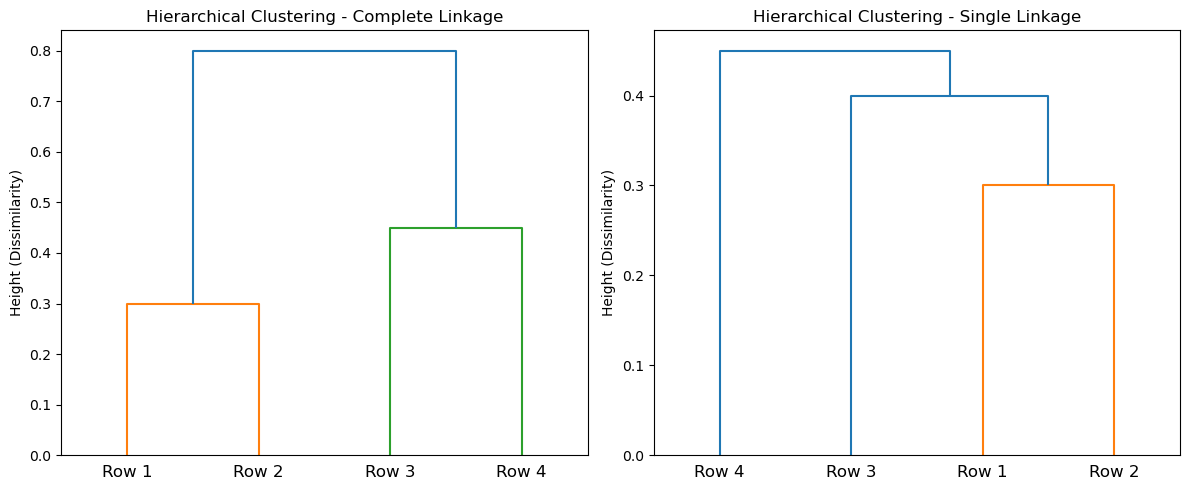

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
import numpy as np

dist_matrix = np.array([
    [0.0,  0.3,  0.4,  0.7],
    [0.3,  0.0,  0.5,  0.8],
    [0.4,  0.5,  0.0,  0.45],
    [0.7,  0.8,  0.45, 0.0]
])

condensed_dist = squareform(dist_matrix)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (a)
linkage_complete = linkage(condensed_dist, method='complete')
dendrogram(linkage_complete, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[0])
axes[0].set_title('Hierarchical Clustering - Complete Linkage')
axes[0].set_ylabel('Height (Dissimilarity)')

# (b)
linkage_single = linkage(condensed_dist, method='single')
dendrogram(linkage_single, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[1])
axes[1].set_title('Hierarchical Clustering - Single Linkage')
axes[1].set_ylabel('Height (Dissimilarity)')

plt.tight_layout()
plt.show()

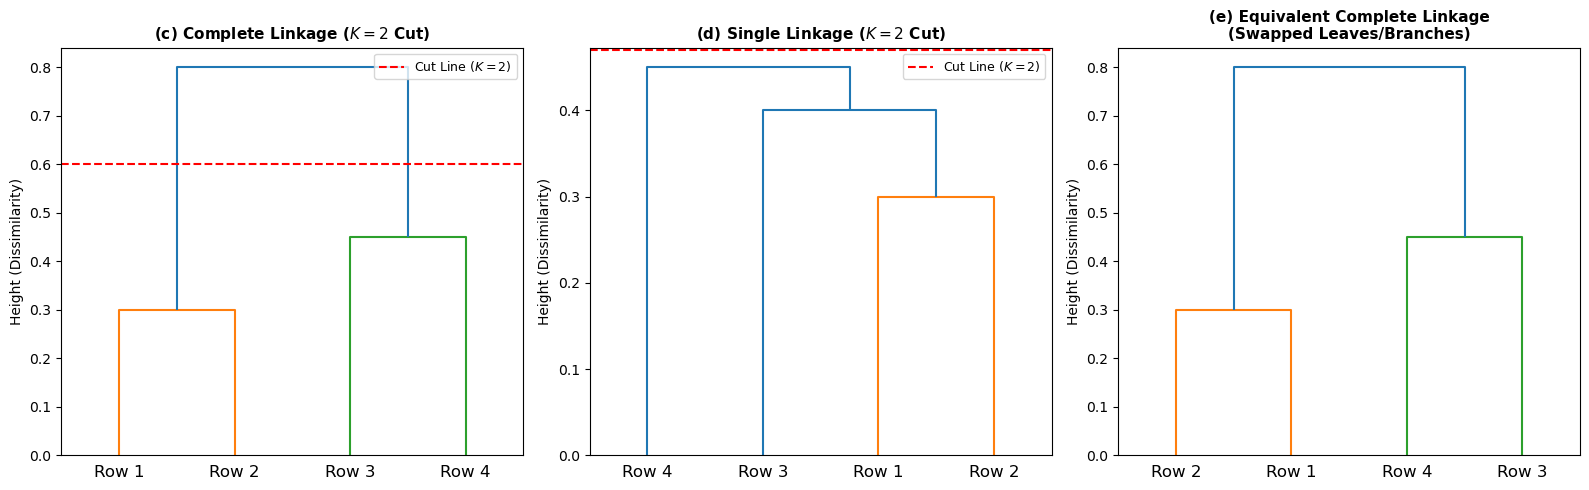

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (c) Complete Linkage Cut for K=2 
linkage_complete = linkage(condensed_dist, method='complete')
dendrogram(linkage_complete, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[0])
axes[0].set_title('(c) Complete Linkage ($K=2$ Cut)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Height (Dissimilarity)')
# Add a horizontal cut line that splits the tree into 2 clusters: {1,2} and {3,4}
axes[0].axhline(y=0.6, color='red', linestyle='--', linewidth=1.5, label='Cut Line ($K=2$)')
axes[0].legend(loc='upper right', fontsize=9)

#(d) Single Linkage Cut for K=2 
linkage_single = linkage(condensed_dist, method='single')
dendrogram(linkage_single, labels=['Row 1', 'Row 2', 'Row 3', 'Row 4'], ax=axes[1])
axes[1].set_title('(d) Single Linkage ($K=2$ Cut)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Height (Dissimilarity)')
# Add a horizontal cut line that splits the tree into 2 clusters: {1,2,3} and {4}
axes[1].axhline(y=0.47, color='red', linestyle='--', linewidth=1.5, label='Cut Line ($K=2$)')
axes[1].legend(loc='upper right', fontsize=9)

#(e) Equivalent Complete Linkage with Swapped Leaves 
dendrogram(
    linkage_complete, 
    labels=['Row 2', 'Row 1', 'Row 4', 'Row 3'],  
    ax=axes[2]
)
axes[2].set_title('(e) Equivalent Complete Linkage\n(Swapped Leaves/Branches)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Height (Dissimilarity)')

plt.tight_layout()
plt.show()

Exercise 3:

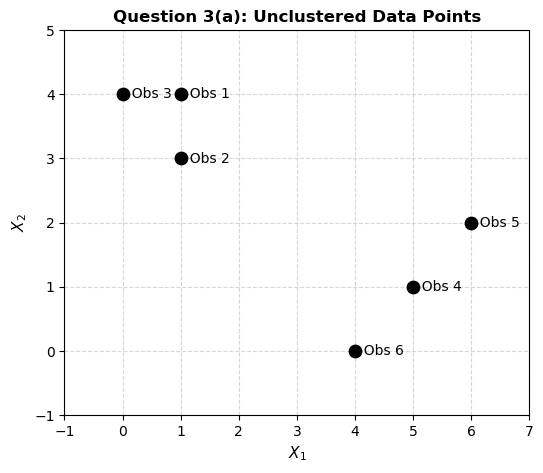

In [16]:
#(a)
X = np.array([
    [1, 4],  
    [1, 3],  
    [0, 4],  
    [5, 1],  
    [6, 2],  
    [4, 0]   
])

obs_labels = [1, 2, 3, 4, 5, 6]


plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], color='black', s=80, zorder=3)


for i, txt in enumerate(obs_labels):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Question 3(a): Unclustered Data Points', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

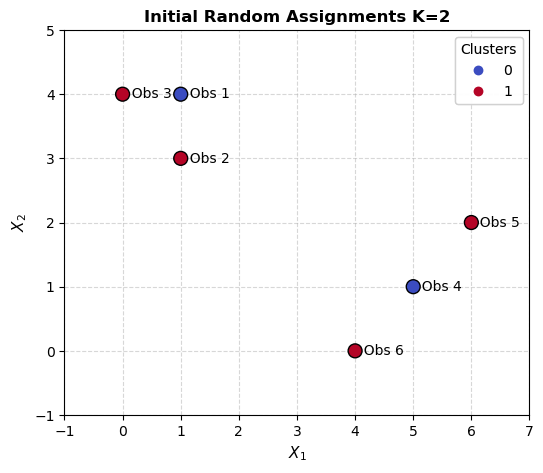

In [17]:
#(b)
np.random.seed(0)
initial_labels = np.random.choice([0, 1], size=len(X))

plt.figure(figsize=(6, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=initial_labels, cmap='coolwarm', s=100, edgecolor='k', zorder=3)
legend1 = plt.legend(*scatter.legend_elements(), title="Clusters")
plt.gca().add_artist(legend1)

for i, txt in enumerate(range(1, 7)):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Initial Random Assignments K=2', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [20]:
#(c)




centroid_0 = np.mean(X[initial_labels == 0], axis=0)
centroid_1 = np.mean(X[initial_labels == 1], axis=0)

print(f"Cluster 0 members: {np.where(initial_labels == 0)[0] + 1}")
print(f"Cluster 0 Centroid: {centroid_0}")
print("-" * 20)
print(f"Cluster 1 members: {np.where(initial_labels == 1)[0] + 1}")
print(f"Cluster 1 Centroid: {centroid_1}")



Cluster 0 members: [1 4]
Cluster 0 Centroid: [3.  2.5]
--------------------
Cluster 1 members: [2 3 5 6]
Cluster 1 Centroid: [2.75 2.25]


In [22]:
#(d)
def assign_clusters(X, c0, c1):
    new_labels = []
    for x in X:
        d0 = np.linalg.norm(x - c0)
        d1 = np.linalg.norm(x - c1)
        new_labels.append(0 if d0 < d1 else 1)
    return np.array(new_labels)

updated_labels = assign_clusters(X, centroid_0, centroid_1)

print("Updated Cluster Assignments after Distance Comparison:")
for i, label in enumerate(updated_labels, start=1):
    print(f"Observation {i} -> Assigned to Cluster {label}")



Updated Cluster Assignments after Distance Comparison:
Observation 1 -> Assigned to Cluster 1
Observation 2 -> Assigned to Cluster 1
Observation 3 -> Assigned to Cluster 1
Observation 4 -> Assigned to Cluster 0
Observation 5 -> Assigned to Cluster 0
Observation 6 -> Assigned to Cluster 1


In [23]:
#(e)

np.random.seed(42)
labels = np.random.choice([0, 1], size=len(X))
iteration = 0
converged = False

print("Starting K-means Iterative Optimization:\n" + "-"*40)

while not converged:
    iteration += 1
    c0 = np.mean(X[labels == 0], axis=0)
    c1 = np.mean(X[labels == 1], axis=0)
    

    new_labels = []
    for x in X:
        d0 = np.linalg.norm(x - c0)
        d1 = np.linalg.norm(x - c1)
        new_labels.append(0 if d0 < d1 else 1)
    new_labels = np.array(new_labels)
    
    print(f"Iteration {iteration}:")
    print(f"  Cluster 0 Centroid: {c0}, Members: {np.where(labels == 0)[0] + 1}")
    print(f"  Cluster 1 Centroid: {c1}, Members: {np.where(labels == 1)[0] + 1}")
    print(f"  New Labels: {new_labels}\n")
    
    if np.array_equal(labels, new_labels):
        converged = True
        print(f"Algorithm converged after {iteration} iterations!")
    else:
        labels = new_labels

Starting K-means Iterative Optimization:
----------------------------------------
Iteration 1:
  Cluster 0 Centroid: [3.   2.75], Members: [1 3 4 5]
  Cluster 1 Centroid: [2.5 1.5], Members: [2 6]
  New Labels: [0 0 0 1 0 1]

Iteration 2:
  Cluster 0 Centroid: [2.   3.25], Members: [1 2 3 5]
  Cluster 1 Centroid: [4.5 0.5], Members: [4 6]
  New Labels: [0 0 0 1 1 1]

Iteration 3:
  Cluster 0 Centroid: [0.66666667 3.66666667], Members: [1 2 3]
  Cluster 1 Centroid: [5. 1.], Members: [4 5 6]
  New Labels: [0 0 0 1 1 1]

Algorithm converged after 3 iterations!


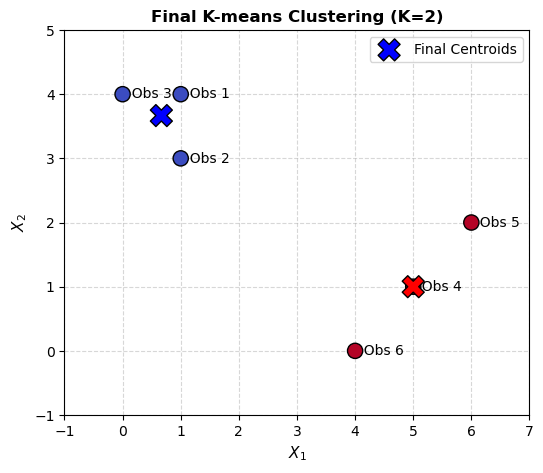

In [24]:
#(f)


final_labels = np.array([0, 0, 0, 1, 1, 1]) 
final_c0 = np.mean(X[final_labels == 0], axis=0)
final_c1 = np.mean(X[final_labels == 1], axis=0)


plt.figure(figsize=(6, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=final_labels, cmap='coolwarm', s=120, edgecolor='k', zorder=3)
plt.scatter([final_c0[0], final_c1[0]], [final_c0[1], final_c1[1]], 
            color=['blue', 'red'], marker='X', s=250, edgecolor='k', label='Final Centroids', zorder=4)

for i, txt in enumerate(range(1, 7)):
    plt.annotate(f'  Obs {txt}', (X[i, 0], X[i, 1]), fontsize=10, verticalalignment='center')

plt.title('Final K-means Clustering (K=2)', fontsize=12, fontweight='bold')
plt.xlabel('$X_1$', fontsize=11)
plt.ylabel('$X_2$', fontsize=11)
plt.xlim(-1, 7)
plt.ylim(-1, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

Exercise 4

(a)

*Answer:*
The fusion for *complete linkage* will occur *higher* on the tree than for single linkage.

* Reasoning:
*Single Linkage* defines the dissimilarity between two clusters $A$ and $B$ as the minimum pairwise distance between points in the two clusters: $d_{\text{single}}(A, B) = \min_{i \in A, j \in B} d(i, j)$


*Complete Linkage* defines the dissimilarity as the *maximum* pairwise distance between points in the two clusters:$d_{\text{complete}}(A, B) = \max_{i \in A, j \in B} d(i, j)$

so, the fusion height for complete linkage will always be at or above the fusion height for single linkage:



(b)

*Answer:**
They will fuse at the *exact same height*.

* Reasoning:
When fusing two clusters that each consist of a **single observation** (i.e., singleton clusters like $\{5\}$ and $\{6\}$), there is only one pair of points to compare ($i=5$ and $j=6$). 

Therefore, the minimum distance and the maximum distance between them are identical:
$ \min(d(5,6)) = \max(d(5,6)) = d(5,6) $

Because both linkage methods collapse to the exact same pairwise distance for singletons, the fusion height is identical on both dendrograms.

Exercise 5: 


* Left Plot: Raw Variables (Number of Items Purchased)


The clustering will be entirely driven by the number of socks purchased, while computer purchases will have virtually no effect. 
so, the number of socks purchased ranges roughly from 5 to 11, whereas the number of computers purchased ranges only from 0 to 1. Because Euclidean distance is sensitive to the scale of the data, the much larger numerical variance in sock purchases completely dominates the distance calculations, rendering computer purchases statistically negligible.



* Center Plot: Variables Scaled by Standard Deviation (Z-score Scaling)


The clustering will take **both products into balanced consideration**, grouping shoppers based on a combined measure of their relative purchasing behaviors for both socks and computers.
Each variable is scaled by its standard deviation, meaning both socks and computers are given comparable variance and equal weight in the Euclidean distance calculation. Neither variable dominates, so the clusters reflect true combined shopping habits across both items

* Right Plot: Monetary Value (Dollars Spent)


The clustering will be entirely driven by computer purchases (dollars spent on computers), while sock purchases will become completely invisible.
Since a computer costs vastly more than a pair of socks, the scale of dollars spent on computers stretches into thousands (0 to over 1500), whereas money spent on socks remains a tiny fraction (< 100). Consequently, the massive variance in monetary value for computers will entirely dominate the inter-observation Euclidean distances, completely overriding the sock purchase history

Exercise 6:



1. **Rewriting the Optimization Problem:**
   In PCA approximation, equation (12.6) seeks to minimize the reconstruction error of the data matrix $\mathbf{X}$ using rank-$M$ matrix factorization:
   
   $$
   \min_{\mathbf{A} \in \mathbb{R}^{n \times M}, \mathbf{B} \in \mathbb{R}^{p \times M}} \left\{ \sum_{j=1}^p \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M a_{im} b_{jm} \right)^2 \right\}
   $$

   Here:
   * $a_{im} = z_{im}$ are the elements of the score vectors (known predictors).
   * $b_{jm} = \phi_{jm}$ are the elements of the loading vectors (unknown coefficients to estimate).
   * $x_{ij}$ represents the feature values of the data matrix.

2. **Decoupling Across Features ($j$):**
   Notice that the outer sum runs over each feature $j$ from $1$ to $p$. The choice of loading coefficients for a specific feature $j$ (i.e., $b_{j1}, b_{j2}, \dots, b_{jM}$) only affects the $j$-th term inside the summation:
   
   $$
   \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M z_{im} \phi_{jm} \right)^2
   $$

   Because the minimization problem is a sum over independent features $j = 1, \dots, p$, **minimizing the total objective function is mathematically equivalent to minimizing each feature's squared error separately.**

3. **Formulation as Ordinary Least Squares (OLS):**
   For any given feature $j$, the expression:
   
   $$
   \sum_{i=1}^n \left( x_{ij} - \sum_{m=1}^M z_{im} \phi_{jm} \right)^2
   $$

   is precisely the sum of squared residuals for a linear regression model where:
   * **The response variable** is the $j$-th feature column of the data matrix, $y_j = (x_{1j}, x_{2j}, \dots, x_{nj})^T$.
   * **The predictors** are the $M$ principal component score vectors, $z_{im}$ for $m = 1, \dots, M$.
   * **The regression coefficients** to be estimated are the loading vector components, $\phi_{j1}, \phi_{j2}, \dots, \phi_{jM}$ (with no intercept, as PCA assumes centered features).


if the score vectors $z_{im}$ are known, each of the $p$ feature loading vectors can be obtained independently by running **$p$ separate multiple linear regressions** (one for each feature $x_{\cdot j}$ against the $M$ score vectors $z_{\cdot m}$), where the resulting regression coefficients correspond directly to the principal component loadings $\phi_{jm}$. 